# RetailPulse — Step 5: Demand Forecasting (baselines, Prophet, LSTM, hybrid)

**Goal:** compare simple baselines, Prophet, an LSTM and a hybrid on the same test weeks, then produce a 30-day forecast with uncertainty,
plus weekly unit forecasts for the top 20 products (used by Step 6 inventory).

**Target = units sold.** Store-wide promotions cut revenue but not units (Steps 1–2), so units are the better measure of demand.

**Evaluation design (fixed before modelling):**

| Split | Period | Purpose |
|---|---|---|
| Train | 1 Jan 2022 – 7 Sep 2025 | fit models |
| Validation | 8 Sep – 2 Nov 2025 (8 weeks) | choose model settings and hybrid weights |
| Test | 3 Nov – 28 Dec 2025 (last 8 full weeks) | final accuracy, used once |

Every model forecasts **7 days ahead from each Monday** in the period (rolling origin), using only data before that Monday — the way a store plans next week every week.
Headline metric: **WAPE** (total absolute error ÷ total units) on weekly totals. Code: `src/forecasting.py`, `src/metrics.py`.

## 0. Setup

In [1]:
import os, sys, json, time, logging, warnings
os.environ.update(TF_CPP_MIN_LOG_LEVEL='3', TF_ENABLE_ONEDNN_OPTS='0')   # quiet TensorFlow start-up messages
logging.getLogger('tensorflow').addFilter(lambda r: 'GPU support is not available' not in r.getMessage())
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore', category=FutureWarning)

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.cleaning import connect
from src.metrics import forecast_metrics
from src.forecasting import (calendar, promo_calendar, lost_units, rolling_origin, naive_last_week, last_year_with_growth,
                             prophet_model, prophet_predict, train_lstm, lstm_forecast, F)

PROC, MODELS = ROOT / 'data' / 'processed', ROOT / 'models'
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.2f}'.format); pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'

con = connect(ROOT / 'retail_clean_dataset', PROC / 'sales_clean.parquet')
daily = pd.read_csv(PROC / 'daily_sales_features.csv', parse_dates=['date'], index_col='date')
y = daily['units'].astype(float)

VAL_START, TEST_START, TEST_END = pd.Timestamp('2025-09-08'), pd.Timestamp('2025-11-03'), pd.Timestamp('2025-12-28')
cal = calendar()
disc = promo_calendar(con, cal.index)
regs = cal[['m1', 'm2', 'm11', 'm12']].assign(disc=disc)          # Prophet regressors (known in advance)
extra = cal.assign(disc=disc / 50)                                  # LSTM calendar inputs
print(f'daily units {y.index.min().date()} -> {y.index.max().date()} ({len(y)} days)')

daily units 2022-01-01 -> 2025-12-31 (1461 days)


## 1. Lost sales from the injected stockouts
Step 2 showed that the known stockout windows fall in Oct–Dec 2025, inside validation and test. Sales lost there were never recorded,
so recorded units **understate real demand**. Each out-of-stock store × SKU is assumed to have sold its average daily units from the 90 days before the stockout.
Models are scored against recorded units (the guide's standard) **and** against this estimated demand.

estimated lost units: 43,845 in total | peak 976/day on 2025-11-15 | 3.0% of Oct-Dec 2025 units


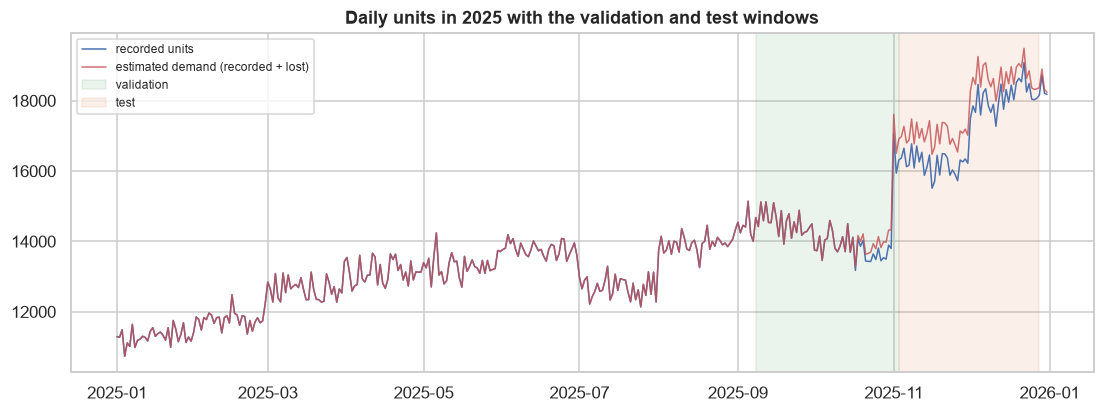

In [2]:
lost = lost_units(con).set_index('date')['lost_units'].reindex(y.index).fillna(0)
demand = y + lost
print(f"estimated lost units: {lost.sum():,.0f} in total | peak {lost.max():,.0f}/day on {lost.idxmax().date()} | "
      f"{lost['2025-10':].sum() / y['2025-10':].sum():.1%} of Oct-Dec 2025 units")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y['2025-01':], lw=1, label='recorded units')
ax.plot(demand['2025-01':], lw=1, color='C3', alpha=.8, label='estimated demand (recorded + lost)')
for a, b, c, t in [(VAL_START, TEST_START, 'C2', 'validation'), (TEST_START, TEST_END, 'C1', 'test')]:
    ax.axvspan(a, b, color=c, alpha=.12, label=t)
ax.set_title('Daily units in 2025 with the validation and test windows'); ax.legend(loc='upper left', fontsize=8)
save('05a_splits_lost_sales'); plt.show()

**Insights — lost sales**
- The stockouts cost an estimated **43,800 units**, about **3% of Oct–Dec 2025 sales**, with a peak of ~980 units/day in mid-November.
- In the chart, recorded units (blue) sit visibly below estimated demand (red) from mid-October to December, which is exactly the validation and test period. A model that matches recorded units perfectly there would be *under*-forecasting real demand, so both scores are reported.

## 2. Baselines
Any model must beat simple rules to be worth using:
- **Naive last week** — next week = last week, day by day.
- **Last year × growth** — same weekday last year, scaled by how much the last 28 days grew versus the same 28 days a year earlier.

In [3]:
def weekly(s):                      # daily -> Mon-Sun weekly totals
    return s.resample('W-SUN').sum()

def score(f, actual=y):
    a = actual.loc[f.index]
    return {'daily WAPE %': forecast_metrics(a, f)['WAPE_%'], 'weekly WAPE %': forecast_metrics(weekly(a), weekly(f))['WAPE_%'],
            'weekly MAPE %': forecast_metrics(weekly(a), weekly(f))['MAPE_%'], 'weekly RMSE': forecast_metrics(weekly(a), weekly(f))['RMSE']}

fc = {'val': {}, 'test': {}}
for name, fn in [('Naive last week', naive_last_week), ('Last year x growth', last_year_with_growth)]:
    for split, start in [('val', VAL_START), ('test', TEST_START)]:
        fc[split][name] = rolling_origin(fn, y, start)
pd.DataFrame({n: score(f) for n, f in fc['val'].items()}).T.rename_axis('validation')

,daily WAPE %,weekly WAPE %,weekly MAPE %,weekly RMSE
validation,,,,
Naive last week,3.24,2.08,2.07,"2,592.40"
Last year x growth,2.93,1.57,1.56,"2,200.49"


## 3. Prophet
Prophet models trend + yearly + weekly seasonality. Demand **jumps** at the start of November and drops on 1 January (Step 2), which a smooth yearly curve
cannot follow, so the main version adds known-in-advance regressors: month flags for Jan, Feb, Nov and Dec, and the store-wide discount %.
Seasonality is multiplicative (it grows with the trend). Prophet is refit at every weekly origin. The variant is chosen on **validation**.

In [4]:
def prophet_rolling(start, use_regs=True, intervals=False):
    parts = []
    for o in pd.date_range(start, periods=8, freq='7D'):
        r = regs if use_regs else regs[[]]
        m = prophet_model(y.loc[:o - pd.Timedelta(days=1)], r)
        parts.append(prophet_predict(m, pd.date_range(o, periods=F), r))
    out = pd.concat(parts)
    return out if intervals else out['yhat']

t = time.time()
variants = {'Prophet (no regressors)': prophet_rolling(VAL_START, use_regs=False),
            'Prophet + month flags + discount': prophet_rolling(VAL_START)}
print(f'{time.time() - t:.0f}s')
pd.DataFrame({n: score(f) for n, f in variants.items()}).T.rename_axis('validation')

7s


,daily WAPE %,weekly WAPE %,weekly MAPE %,weekly RMSE
validation,,,,
Prophet (no regressors),3.42,2.53,2.54,"3,031.02"
Prophet + month flags + discount,2.09,1.23,1.24,"1,517.30"


In [5]:
fc['val']['Prophet'] = variants['Prophet + month flags + discount']
prophet_test = prophet_rolling(TEST_START, intervals=True)
fc['test']['Prophet'] = prophet_test['yhat']

**Insights — Prophet**
- Adding the month flags and the discount roughly **halves Prophet's validation error** (weekly WAPE 2.5% → 1.2%). A smooth yearly curve cannot follow demand that jumps on 1 November and drops on 1 January; explicit flags can.
- These inputs are all known in advance (calendar and planned promotions), so they can be used for real future forecasts.

## 4. LSTM
A small neural network (TensorFlow/Keras) that forecasts the next 7 days in one go:
- **history input:** the last 56 days of units (divided by the recent 28-day level, so the network learns *shape*, not size) and the discount;
- **future input:** for each of the 7 days, the same weekday last year (relative to last year's level), month flags, weekday and the planned discount.

It is trained on every daily origin with enough history (~950 samples), with early stopping on the last 15% of the training period.
One model is trained for validation (data before 8 Sep) and one for test (data before 3 Nov); both then roll forward week by week using actual history, without refitting.
Seeds and deterministic operations make results repeatable.

In [6]:
t = time.time()
lstm_val = train_lstm(y, extra, last_origin=VAL_START - pd.Timedelta(days=F))
fc['val']['LSTM'] = lstm_forecast(lstm_val, y, extra, pd.date_range(VAL_START, periods=8, freq='7D'))
lstm_test = train_lstm(y, extra, last_origin=TEST_START - pd.Timedelta(days=F))
fc['test']['LSTM'] = lstm_forecast(lstm_test, y, extra, pd.date_range(TEST_START, periods=8, freq='7D'))
print(f'two LSTMs trained in {time.time() - t:.0f}s')
pd.DataFrame({n: score(f) for n, f in fc['val'].items()}).T.rename_axis('validation')

two LSTMs trained in 181s


,daily WAPE %,weekly WAPE %,weekly MAPE %,weekly RMSE
validation,,,,
Naive last week,3.24,2.08,2.07,"2,592.40"
Last year x growth,2.93,1.57,1.56,"2,200.49"
Prophet,2.09,1.23,1.24,"1,517.30"
LSTM,2.39,1.20,1.19,"1,455.49"


## 5. Hybrid (weights chosen on validation)
Hybrid = *w* × Prophet + (1 − *w*) × LSTM. The weight *w* is chosen on the **validation** weeks only, then applied unchanged to test.

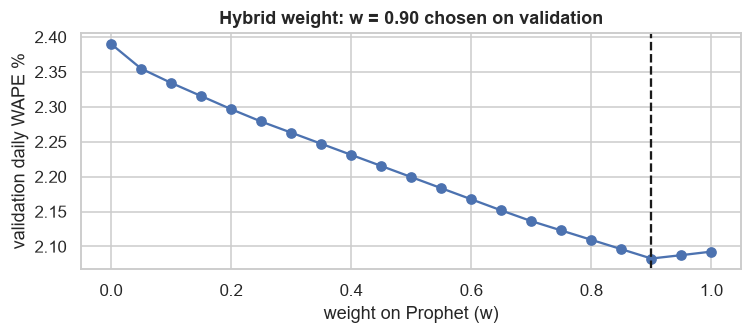

In [7]:
grid = np.round(np.arange(0, 1.01, 0.05), 2)
wscores = pd.Series({w: score(w * fc['val']['Prophet'] + (1 - w) * fc['val']['LSTM'])['daily WAPE %'] for w in grid})
W = float(wscores.idxmin())
for split in ['val', 'test']:
    fc[split]['Hybrid'] = W * fc[split]['Prophet'] + (1 - W) * fc[split]['LSTM']

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(wscores.index, wscores.values, 'o-'); ax.axvline(W, color='k', ls='--')
ax.set_xlabel('weight on Prophet (w)'); ax.set_ylabel('validation daily WAPE %'); ax.set_title(f'Hybrid weight: w = {W:.2f} chosen on validation')
plt.tight_layout(); plt.show()

## 6. Final comparison on the test weeks (used once)

In [8]:
ORDER = ['Naive last week', 'Last year x growth', 'Prophet', 'LSTM', 'Hybrid']
rows = []
for n in ORDER:
    v, t_rec, t_dem = score(fc['val'][n]), score(fc['test'][n]), score(fc['test'][n], demand)
    rows.append({'model': n, 'val weekly WAPE %': v['weekly WAPE %'], 'test daily WAPE %': t_rec['daily WAPE %'],
                 'test weekly WAPE %': t_rec['weekly WAPE %'], 'test weekly MAPE %': t_rec['weekly MAPE %'],
                 'test weekly RMSE': t_rec['weekly RMSE'], 'test weekly WAPE % vs est. demand': t_dem['weekly WAPE %']})
comparison = pd.DataFrame(rows).set_index('model')
comparison.to_csv(PROC / 'forecast_comparison.csv', float_format=FLOAT)
comparison

,val weekly WAPE %,test daily WAPE %,test weekly WAPE %,test weekly MAPE %,test weekly RMSE,test weekly WAPE % vs est. demand
model,,,,,,
Naive last week,2.08,4.46,3.38,3.37,"6,674.51",6.50
Last year x growth,1.57,2.75,2.20,2.18,"3,047.84",4.13
Prophet,1.23,2.78,2.42,2.48,"3,324.51",2.74
LSTM,1.20,2.81,2.47,2.48,"3,675.28",3.96
Hybrid,1.20,2.73,2.42,2.47,"3,285.37",2.86


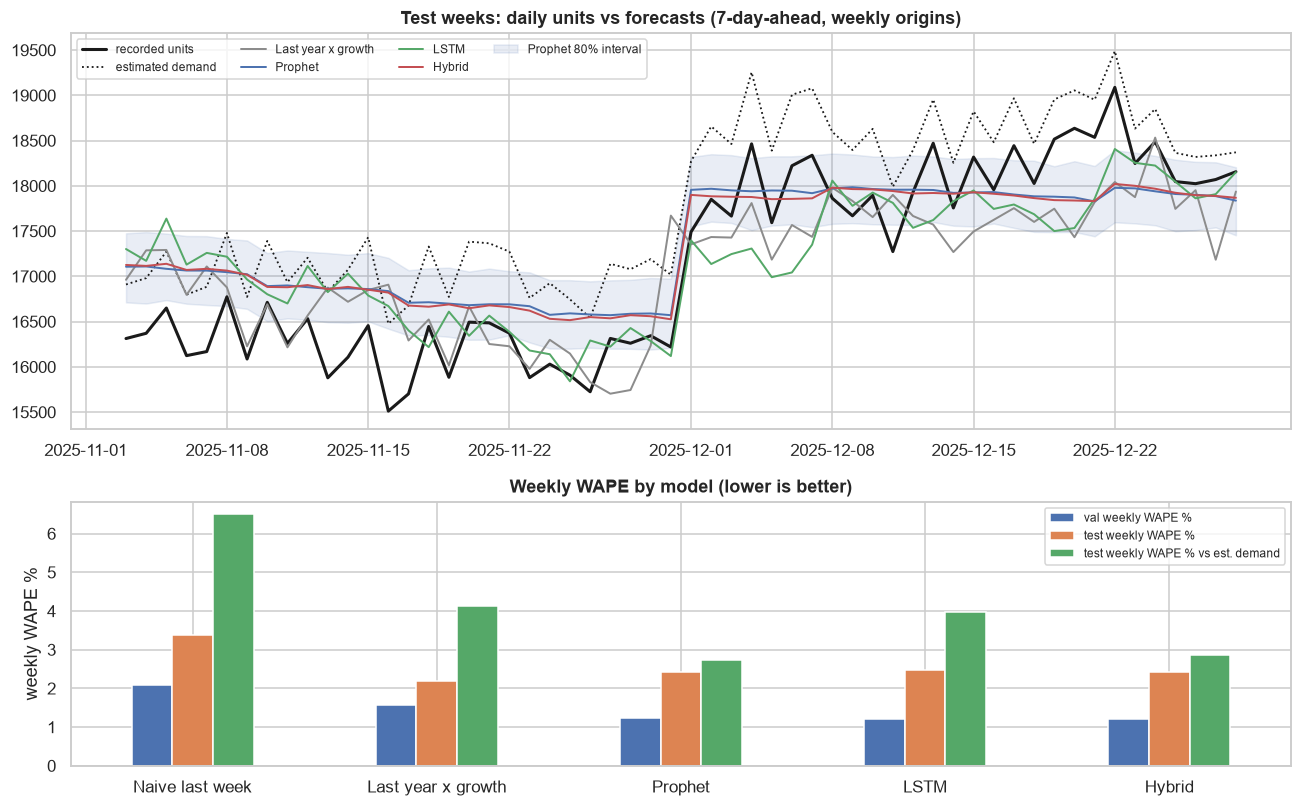

Prophet 80% interval covered only 48% of test days


In [9]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), gridspec_kw={'height_ratios': [3, 2]})
a = y.loc[TEST_START:TEST_END]
ax[0].plot(a.index, a, 'k', lw=2, label='recorded units')
ax[0].plot(a.index, demand.loc[a.index], 'k:', lw=1.2, label='estimated demand')
for n, c in zip(['Last year x growth', 'Prophet', 'LSTM', 'Hybrid'], ['C7', 'C0', 'C2', 'C3']):
    ax[0].plot(fc['test'][n].index, fc['test'][n], color=c, lw=1.3, label=n)
ax[0].fill_between(prophet_test.index, prophet_test['yhat_lower'], prophet_test['yhat_upper'], color='C0', alpha=.12, label='Prophet 80% interval')
ax[0].set_title('Test weeks: daily units vs forecasts (7-day-ahead, weekly origins)'); ax[0].legend(ncol=4, fontsize=8, loc='upper left')
comparison[['val weekly WAPE %', 'test weekly WAPE %', 'test weekly WAPE % vs est. demand']].plot.bar(ax=ax[1], rot=0)
ax[1].set_ylabel('weekly WAPE %'); ax[1].set_xlabel(''); ax[1].set_title('Weekly WAPE by model (lower is better)')
ax[1].legend(fontsize=8)
plt.tight_layout(); save('05b_test_forecasts'); plt.show()

inside = ((a >= prophet_test['yhat_lower']) & (a <= prophet_test['yhat_upper'])).mean()
print(f'Prophet 80% interval covered only {inside:.0%} of test days')

**Forecast range.** Prophet's own 80% interval is too narrow (it covers far fewer than 80% of test days), so the range used for planning is built
from the hybrid's **actual errors** instead: the 10th and 90th percentiles of (estimated demand ÷ forecast − 1) over the 16 validation and test weeks.

In [10]:
hyb = pd.concat([fc['val']['Hybrid'], fc['test']['Hybrid']])
rel_err = demand.loc[hyb.index] / hyb - 1
Q10, Q90 = rel_err.quantile([0.1, 0.9])
print(f'hybrid relative error, 10th-90th percentile: {Q10:+.1%} to {Q90:+.1%} '
      f'(average {rel_err.mean():+.1%}: forecasts sit below estimated demand)')

hybrid relative error, 10th-90th percentile: -2.1% to +4.4% (average +1.4%: forecasts sit below estimated demand)


**Insights — model comparison**
- **All models are accurate:** weekly error is 2.2–3.4% on the test weeks. Demand here is very regular (steady growth plus a stable yearly pattern), so even simple rules do well.
- **On validation, Prophet, the LSTM and the hybrid (1.2%) beat both baselines (1.6% and 2.1%).** The hybrid weight chosen on validation is **w = 0.9**, mostly Prophet. The LSTM adds little because both models learn the same pattern, so the hybrid ends up about as accurate as Prophet alone.
- **On test, measured against recorded units, "Last year × growth" scores slightly best (2.2% vs 2.4%).** This is partly luck from the stockouts: its growth factor comes from the last 28 days, which were lowered by stockouts in November, so it forecasts low and happens to match the depressed recorded sales.
- **Measured against estimated demand, Prophet (2.7%) and the hybrid (2.9%) are clearly best**, while the baseline (4.1%) and the LSTM (4.0%) under-forecast. For planning stock, demand is what matters, so **the hybrid is used for the final forecast.**
- All models sit below estimated demand in December (by about 1.4% on average), because their training history in Oct–Nov included the stockout-reduced sales. The final models are therefore trained on estimated demand.
- Prophet's own 80% interval covered only 50% of test days, which is too optimistic, so the planning range uses the hybrid's measured errors instead.

## 7. 30-day forecast (1–30 January 2026)
For planning, the final models are refit on **all** data, using **estimated demand** (recorded + lost) so the stockouts do not drag the forecast down.
Prophet forecasts 30 days directly; the LSTM rolls forward a week at a time, feeding its own forecasts back as history. The hybrid uses the weight from validation.
The 80% range applies the hybrid's error percentiles from section 6. They come from 7-day-ahead forecasts, so the range for the later January days is likely too narrow.

final models fitted in 47s


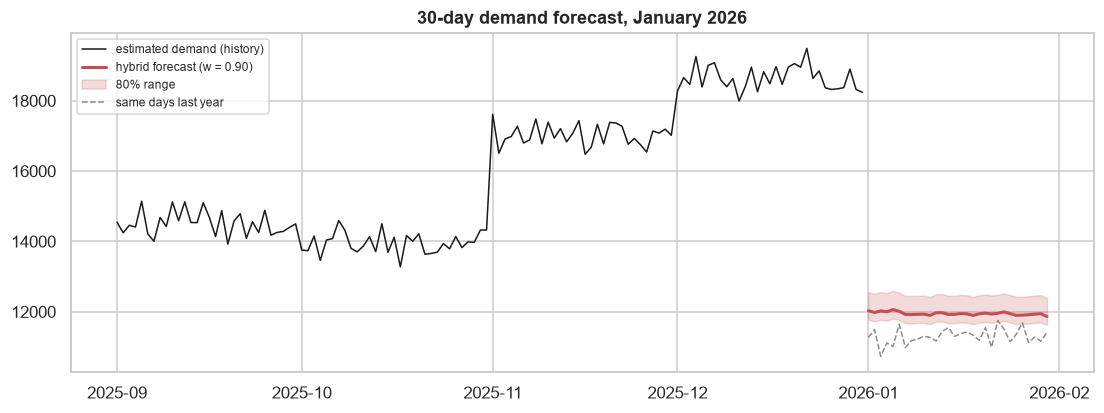

January 2026 (30 days): 358,465 units forecast (80% range 350,964 - 374,304) vs 338,994 in the same days of 2025


In [11]:
t = time.time()
H_DAYS = pd.date_range('2026-01-01', periods=30)
p_final = prophet_model(demand, regs)
p30 = prophet_predict(p_final, H_DAYS, regs)

lstm_final = train_lstm(demand, extra, last_origin=demand.index[-1] - pd.Timedelta(days=F - 1))
hist = demand.copy(); l30 = []
for o in pd.date_range(H_DAYS[0], periods=5, freq='7D'):          # 5 weeks covers 30 days
    step = lstm_forecast(lstm_final, hist, extra, [o]); l30.append(step); hist = pd.concat([hist, step])
l30 = pd.concat(l30).loc[H_DAYS]

f30 = pd.DataFrame({'prophet': p30['yhat'], 'lstm': l30})
f30['forecast'] = W * f30['prophet'] + (1 - W) * f30['lstm']
f30['lower_80'] = f30['forecast'] * (1 + Q10)
f30['upper_80'] = f30['forecast'] * (1 + Q90)
print(f'final models fitted in {time.time() - t:.0f}s')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(demand['2025-09':], color='k', lw=1, label='estimated demand (history)')
ax.plot(f30.index, f30['forecast'], color='C3', lw=2, label=f'hybrid forecast (w = {W:.2f})')
ax.fill_between(f30.index, f30['lower_80'], f30['upper_80'], color='C3', alpha=.2, label='80% range')
ly = demand.reindex(H_DAYS - pd.Timedelta(days=364)); ax.plot(H_DAYS, ly.values, color='C7', ls='--', lw=1, label='same days last year')
ax.set_title('30-day demand forecast, January 2026'); ax.legend(loc='upper left', fontsize=8)
save('05c_forecast_30d'); plt.show()

f30.rename_axis('date').to_csv(PROC / 'forecast_30d.csv', float_format=FLOAT)
print(f"January 2026 (30 days): {f30['forecast'].sum():,.0f} units forecast "
      f"(80% range {f30['lower_80'].sum():,.0f} - {f30['upper_80'].sum():,.0f}) vs {ly.sum():,.0f} in the same days of 2025")

**Insights — January 2026 forecast**
- **358,000 units** forecast for 1–30 January 2026 (80% range ~351k–374k), **+5.7% on the same days of 2025**. This is in line with the 4–6% yearly growth seen in Step 1.
- The forecast shows the usual **January drop**: from ~18,500 units/day in December to ~12,000/day, the same step seen every year. Stock levels planned for December would be far too high for January.
- The range is skewed upwards (−2% / +4%) because past forecasts were more often too low than too high.

## 8. Weekly forecasts for the top 20 products
Weekly unit forecasts per SKU feed the Step 6 inventory calculations. Two methods are compared on validation (fit once before 8 Sep, forecast 8 weeks)
and test (fit once before 3 Nov, forecast 8 weeks):
- **Last year × growth** — same week last year × the SKU's growth over the last 8 weeks vs a year earlier;
- **Prophet (weekly)** — yearly seasonality + share of the week's days in Jan/Feb/Nov/Dec + average store-wide discount.

Here the horizon is 1–8 weeks, so errors are larger than the 7-day chain forecasts above. Accuracy is measured against **estimated demand**
(recorded + lost), because every top-20 SKU had stockouts in the test weeks.

In [12]:
skuw = pd.read_csv(PROC / 'sku_weekly.csv', parse_dates=['week_end'])
lost_sku = lost_units(con, by_sku=True)
lost_sku['week_end'] = lost_sku['date'] + pd.to_timedelta(6 - lost_sku['date'].dt.dayofweek, unit='D')
lost_w = lost_sku.groupby(['sku_id', 'week_end'])['lost_units'].sum()
skuw = skuw.join(lost_w, on=['sku_id', 'week_end']).fillna({'lost_units': 0})
skuw['demand'] = skuw['units'] + skuw['lost_units']

wk_index = pd.date_range('2022-01-09', '2026-03-01', freq='W-SUN')
wregs = pd.DataFrame({f'm{m}': cal[f'm{m}'].resample('W-SUN').mean() for m in [1, 2, 11, 12]}).reindex(wk_index)
wregs['disc'] = disc.resample('W-SUN').mean().reindex(wk_index)
SKUS = skuw.drop_duplicates('sku_id').sort_values('revenue_rank')['sku_id'].tolist()

def sku_last_year(hist, weeks):
    growth = hist.iloc[-8:].sum() / hist.iloc[-60:-52].sum()
    return pd.Series(hist.reindex(weeks - pd.Timedelta(weeks=52)).to_numpy() * growth, index=weeks)

def sku_prophet(hist, weeks):
    m = prophet_model(hist, wregs, interval_width=0.8)
    return prophet_predict(m, weeks, wregs)['yhat'].clip(lower=0)

def sku_backtest(start, target='units'):
    weeks = pd.date_range(start + pd.Timedelta(days=6), periods=8, freq='7D')
    out = []
    for s in SKUS:
        ser = skuw[skuw['sku_id'] == s].set_index('week_end')
        hist = ser.loc[:start - pd.Timedelta(days=1), target]
        out.append(pd.DataFrame({'sku_id': s, 'week_end': weeks, 'actual': ser.loc[weeks, 'units'].to_numpy(),
                                 'demand': ser.loc[weeks, 'demand'].to_numpy(),
                                 'Last year x growth': sku_last_year(hist, weeks).to_numpy(),
                                 'Prophet': sku_prophet(hist, weeks).to_numpy()}))
    return pd.concat(out, ignore_index=True)

t = time.time()
sku_val, sku_test = sku_backtest(VAL_START), sku_backtest(TEST_START)
print(f'{2 * len(SKUS)} Prophet fits in {time.time() - t:.0f}s')
sku_scores = pd.DataFrame({m: {'validation WAPE % (vs demand)': forecast_metrics(sku_val['demand'], sku_val[m])['WAPE_%'],
                               'test WAPE % (vs demand)': forecast_metrics(sku_test['demand'], sku_test[m])['WAPE_%'],
                               'test WAPE % (vs recorded)': forecast_metrics(sku_test['actual'], sku_test[m])['WAPE_%']}
                           for m in ['Last year x growth', 'Prophet']}).T
SKU_MODEL = sku_scores['validation WAPE % (vs demand)'].idxmin()
print('chosen on validation:', SKU_MODEL)
sku_scores

40 Prophet fits in 8s
chosen on validation: Prophet


,validation WAPE % (vs demand),test WAPE % (vs demand),test WAPE % (vs recorded)
Last year x growth,6.44,7.51,21.01
Prophet,4.36,4.93,18.35


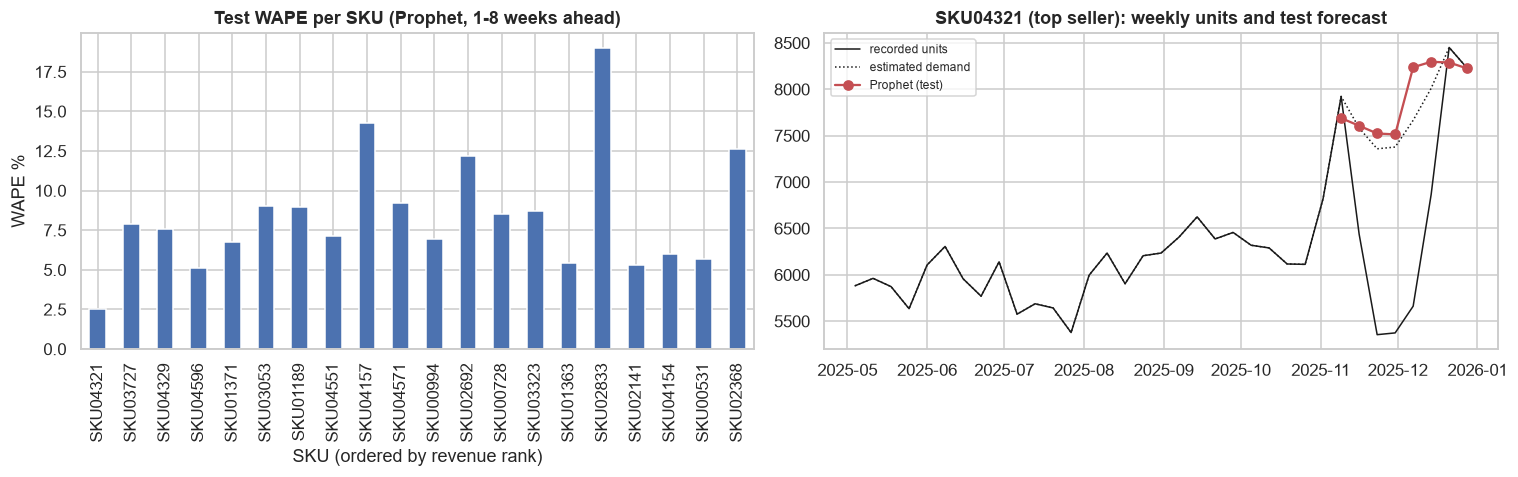

sku_id,SKU04321,SKU03727,SKU04329,SKU04596,SKU01371,SKU03053,SKU01189,SKU04551,SKU04157,SKU04571,SKU00994,SKU02692,SKU00728,SKU03323,SKU01363,SKU02833,SKU02141,SKU04154,SKU00531,SKU02368
WAPE % (vs demand),2.50,7.90,7.60,5.10,6.80,9.00,9.00,7.20,14.30,9.20,6.90,12.20,8.50,8.70,5.50,19.00,5.30,6.00,5.70,12.60
weekly error std,256.20,92.70,24.70,106.30,34.50,11.90,26.60,19.90,29.60,55.40,52.00,20.00,13.50,13.50,7.30,18.70,49.70,49.80,6.40,39.70
avg weekly demand,"7,824.80","1,119.80",276.60,"1,862.70",452.50,139.20,214.90,197.30,181.60,504.60,623.60,169.60,105.60,119.10,116.40,80.70,657.10,862.10,89.50,263.60


In [13]:
per_sku = sku_test.groupby('sku_id').apply(lambda g: pd.Series({
    'WAPE % (vs demand)': forecast_metrics(g['demand'], g[SKU_MODEL])['WAPE_%'],
    'weekly error std': (g['demand'] - g[SKU_MODEL]).std(),
    'avg weekly demand': g['demand'].mean()}), include_groups=False).loc[SKUS]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
per_sku['WAPE % (vs demand)'].plot.bar(ax=ax[0], color='C0'); ax[0].set_title(f'Test WAPE per SKU ({SKU_MODEL}, 1-8 weeks ahead)')
ax[0].set_ylabel('WAPE %'); ax[0].set_xlabel('SKU (ordered by revenue rank)')
s0 = SKUS[0]; g0 = sku_test[sku_test['sku_id'] == s0]; hist0 = skuw[skuw['sku_id'] == s0].set_index('week_end')
ax[1].plot(hist0.loc['2025-05':, 'units'], color='k', lw=1, label='recorded units')
ax[1].plot(hist0.loc['2025-05':, 'demand'], 'k:', lw=1, label='estimated demand')
ax[1].plot(g0['week_end'], g0[SKU_MODEL], 'o-', color='C3', label=f'{SKU_MODEL} (test)')
ax[1].set_title(f'{s0} (top seller): weekly units and test forecast'); ax[1].legend(fontsize=8)
plt.tight_layout(); save('05d_sku_forecasts'); plt.show()
per_sku.round(1).T

In [14]:
# Final SKU forecasts for the next 5 weeks, refit on all weeks of estimated demand
fut_weeks = pd.date_range('2026-01-04', periods=5, freq='W-SUN')
rows = []
for s in SKUS:
    hist = skuw[skuw['sku_id'] == s].set_index('week_end')['demand']
    f = sku_prophet(hist, fut_weeks) if SKU_MODEL == 'Prophet' else sku_last_year(hist, fut_weeks)
    rows.append(pd.DataFrame({'sku_id': s, 'week_end': fut_weeks, 'forecast_units': f.to_numpy()}))
sku_fc = pd.concat(rows, ignore_index=True).merge(per_sku[['weekly error std', 'WAPE % (vs demand)']].rename(
    columns={'weekly error std': 'error_std', 'WAPE % (vs demand)': 'backtest_wape_pct'}), left_on='sku_id', right_index=True)
sku_fc['model'] = SKU_MODEL
sku_fc.to_csv(PROC / 'sku_forecasts.csv', index=False, float_format=FLOAT)
print('saved sku_forecasts.csv', sku_fc.shape)
sku_fc.pivot(index='sku_id', columns='week_end', values='forecast_units').loc[SKUS].round(0).head(10)

saved sku_forecasts.csv (100, 6)


week_end,2026-01-04,2026-01-11,2026-01-18,2026-01-25,2026-02-01
sku_id,,,,,
SKU04321,"6,513.00","5,278.00","5,309.00","5,331.00","5,331.00"
SKU03727,917.00,732.00,740.00,735.00,740.00
SKU04329,231.00,190.00,191.00,192.00,196.00
SKU04596,"1,565.00","1,284.00","1,285.00","1,247.00","1,199.00"
SKU01371,395.00,322.00,320.00,302.00,286.00
SKU03053,112.00,94.00,101.00,102.00,97.00
SKU01189,183.00,155.00,147.00,145.00,144.00
SKU04551,183.00,142.00,128.00,129.00,139.00
SKU04157,148.00,119.00,125.00,129.00,132.00


**Insights — top-20 SKU forecasts**
- **Prophet beats "last year × growth"** on validation (4.4% vs 6.4% WAPE) and on test (4.9% vs 7.5%), measured against estimated demand, so Prophet is used for the SKU forecasts.
- **Scoring against recorded units would be misleading here:** the errors jump to 18–21%, because stockouts removed large parts of each SKU's sales (for the top seller, recorded units fell from ~7,900 to ~5,400 a week in late November, while estimated demand stayed ~7,400). The forecast follows demand, which is what stock planning needs.
- **Accuracy depends on size.** The top seller (`SKU04321`, ~7,800 units/week) is forecast within 2.5%, while small SKUs (~80–120 units/week) range up to 19%. Smaller items therefore need proportionally more safety stock.
- `sku_forecasts.csv` holds 5 weeks of forecasts per SKU plus each SKU's measured weekly error (`error_std`), which Step 6 uses for safety stock. The week ending 4 January is higher because it includes three December days.

## 9. Save models

In [15]:
from prophet.serialize import model_to_json
(MODELS / 'prophet_daily.json').write_text(model_to_json(p_final))
lstm_final.save(MODELS / 'lstm_daily.keras')
(MODELS / 'forecast_config.json').write_text(json.dumps({
    'target': 'daily units (estimated demand = recorded + lost to stockouts)',
    'hybrid_weight_prophet': W, 'range_80_relative': [round(Q10, 4), round(Q90, 4)], 'prophet_regressors': list(regs.columns),
    'sku_model': SKU_MODEL, 'trained_through': str(demand.index[-1].date())}, indent=2))
print('saved models/prophet_daily.json, models/lstm_daily.keras, models/forecast_config.json')

saved models/prophet_daily.json, models/lstm_daily.keras, models/forecast_config.json


**Done-when check (Step 5)**
- ✅ Comparison table with both baselines, Prophet, the LSTM and the hybrid on the same test weeks, scored by WAPE, MAPE and RMSE, against recorded units and estimated demand → `data/processed/forecast_comparison.csv`
- ✅ Hybrid weight chosen on validation, never on test; test used once
- ✅ 30-day forecast with an 80% range (checked against real errors) → `data/processed/forecast_30d.csv`
- ✅ Weekly unit forecasts and error sizes for the top 20 SKUs → `data/processed/sku_forecasts.csv`
- ✅ Models saved: `models/prophet_daily.json`, `models/lstm_daily.keras`, `models/forecast_config.json`

**Carry forward**
- **Step 6 (inventory):** use `sku_forecasts.csv` (forecast + `error_std`) to set safety stock, reorder points and order quantities in units.
- **Step 7 (MLOps):** log these models in MLflow, tune Prophet with Optuna, and monitor the forecast error for drift.